In [2]:
from astropy.io import fits
from astropy.visualization import ZScaleInterval
from pprint import pprint as pp
import numpy as np
import cmastro
import matplotlib.pyplot as plt
from scipy.ndimage import label
import pandas as pd
import seaborn as sns

#import seaborn as sns
sns.set_theme(context='paper', style='ticks', font_scale=1.5, font='serif', palette='deep', color_codes=True)
plt.rcParams['image.origin'] = 'lower'
plt.rcParams['figure.figsize'] = (12,6)

C:\Users\lwrig\AppData\Local\Temp\ipykernel_23388\384425251.py:8: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


Get all the .fts files and sort them

In [3]:
from fileinput import filename
filenames = np.loadtxt('Lab5_ACAM_DATA/filelist', dtype=str, usecols=0)
flats = []
flats_hdu = []
biases = []
biases_hdu = []
science = []
science_hdu = []
for f in filenames:
    file = fits.open(r'Lab5_ACAM_DATA/' + f)
    header = file[0].header
    if header['OBSTYPE'] == 'FLAT':
        # print("-------")
        # print("File Name: ", f)
        # print("Image Type: ", header['OBSTYPE'])
        # print("Image Dimensions: ", file[1].data.shape)
        flats.append(file[1].data)
        flats_hdu.append(file[0].header)
    elif header['OBSTYPE'] == 'BIAS':
        if file[1].shape == (2071, 2148):
            # print("-------")
            # print("File Name: ", f)
            # print("Image Type: ", header['OBSTYPE'])
            # print("Instrument: ", header['INSTRUME'])
            # print("Exposure Time: ", header['EXPTIME'])
            # print("Image Dimensions: ", file[1].data.shape)
            biases.append(file[1].data)
            biases_hdu.append(file[0].header)
    elif header['OBSTYPE'] == 'TARGET':
        # print("-------")
        # print("File Name: ", f)
        # print("Image Type: ", header['OBSTYPE'])
        # print("Instrument: ", header['INSTRUME'])
        # print("Exposure Time: ", header['EXPTIME'])
        # print("Image Dimensions: ", file[1].data.shape)
        science.append(file[1].data)
        science_hdu.append(file[0].header)
        
science_np = np.array(science)
flats_np = np.array(flats)
biases_np = np.array(biases)

In [4]:
# Mask out region outside vignette
threshold = 2200
mask = np.where(flats_np[0] > threshold, True, False)
for i in range(len(flats)):
    flats_np[i] = flats_np[i] / flats_hdu[i]['EXPTIME']
    flats_np[i] *= mask
for i in range(len(science)):
    science_np[i] *= mask

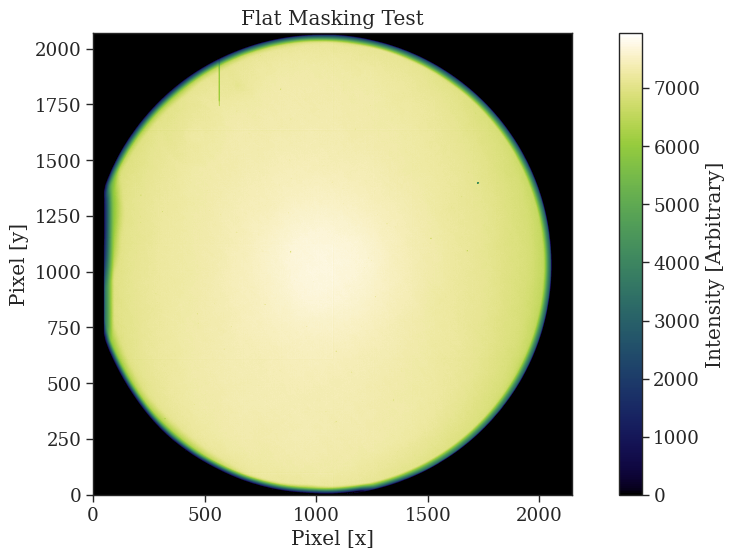

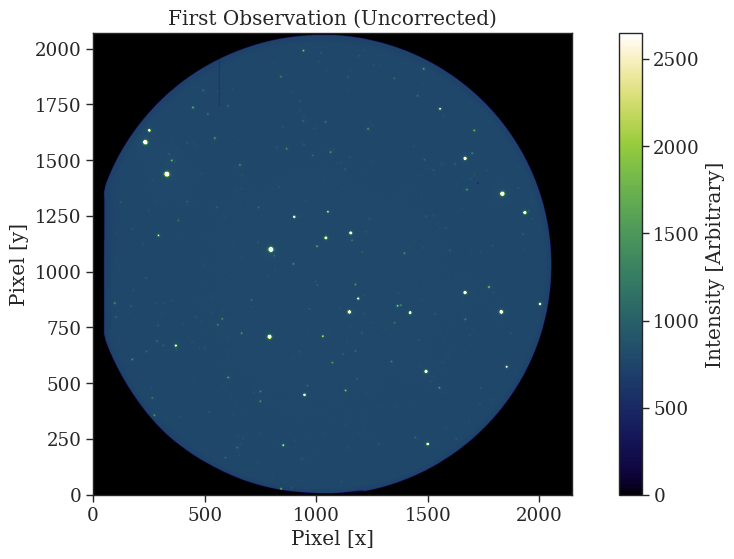

In [5]:
vmin,vmax = ZScaleInterval().get_limits(flats_np[0])
plt.imshow(flats_np[0], cmap='cma:lacerta',
                  vmin=vmin,vmax=vmax)
plt.title("Flat Masking Test")
plt.xlabel("Pixel [x]")
plt.ylabel("Pixel [y]")
plt.colorbar(label="Intensity [Arbitrary]")
plt.show()

# Median bias and flats
median_bias = np.median(biases_np, axis=0)
median_flat = np.median(flats_np, axis=0)
median_flat = (median_flat / np.median(median_flat))

vmin, vmax = ZScaleInterval().get_limits(science_np[0])
plt.imshow(science_np[0], cmap='cma:lacerta', vmin=vmin, vmax=vmax)
plt.title("First Observation (Uncorrected)")
plt.xlabel("Pixel [x]")
plt.ylabel("Pixel [y]")
plt.colorbar(label="Intensity [Arbitrary]")
plt.show()


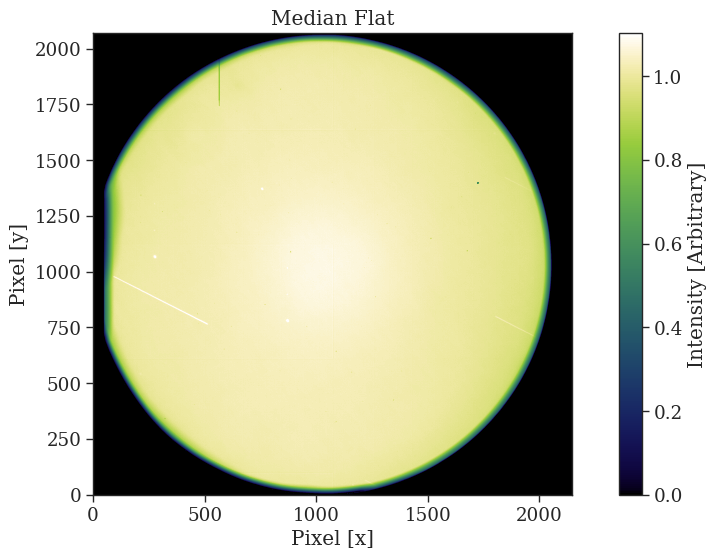

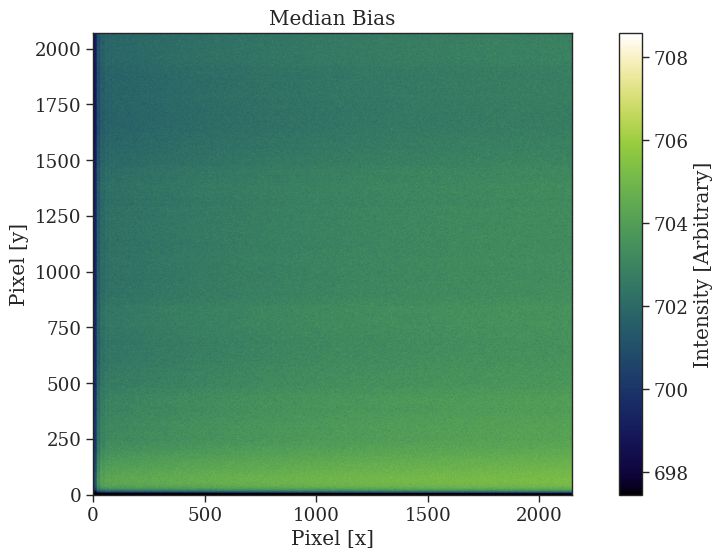

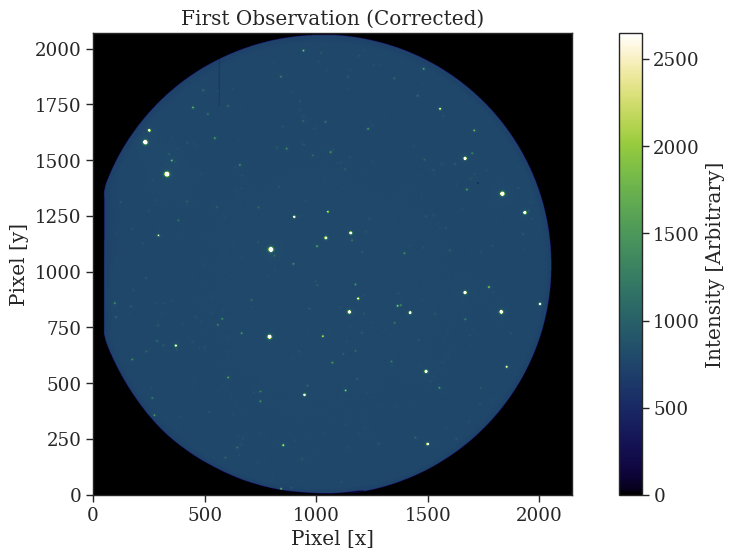

In [6]:
plt.title("Median Flat")
vmin, vmax = ZScaleInterval().get_limits(median_flat)
plt.imshow(median_flat, cmap='cma:lacerta', vmin=vmin, vmax=vmax)
plt.xlabel("Pixel [x]")
plt.ylabel("Pixel [y]")
plt.colorbar(label='Intensity [Arbitrary]')
plt.show()

plt.title("Median Bias")
vmin, vmax = ZScaleInterval().get_limits(median_bias)
plt.imshow(median_bias, cmap='cma:lacerta', vmin=vmin, vmax=vmax)
plt.xlabel("Pixel [x]")
plt.ylabel("Pixel [y]")
plt.colorbar(label='Intensity [Arbitrary]')
plt.show()

plt.title("First Observation (Corrected)")
vmin, vmax = ZScaleInterval().get_limits(science_np[0])
plt.imshow(science_np[0], cmap='cma:lacerta', vmin=vmin, vmax=vmax)
plt.xlabel("Pixel [x]")
plt.ylabel("Pixel [y]")
plt.colorbar(label='Intensity [Arbitrary]')
plt.show()    

In [7]:
for i in range(len(science)):
    science_np[i] = (science_np[i] - median_bias) / median_flat

C:\Users\lwrig\AppData\Local\Temp\ipykernel_23388\227141899.py:2: RuntimeWarning: divide by zero encountered in divide
  science_np[i] = (science_np[i] - median_bias) / median_flat
C:\Users\lwrig\AppData\Local\Temp\ipykernel_23388\227141899.py:2: RuntimeWarning: invalid value encountered in cast
  science_np[i] = (science_np[i] - median_bias) / median_flat


In [8]:
from scipy.optimize import curve_fit

def star_gaussian(stars, image, size=10, filter=False): 
    uncertainties = []   
    centroids_x_coords = []
    centroids_y_coords = []
    initial_cen_x = []
    initial_cen_y = []
    app_radiuses = []

    failed_fittings = 0
    size = size
    
    # 2d gaussian
    def gauss(xy, a, x0, y0, sigma_x, sigma_y, c):
        x, y = xy
        g = a*np.exp(-(x-x0)**2/(2*sigma_x**2) - (y-y0)**2/(2*sigma_y**2)) + c
        return g.ravel()

    for i in range(len(stars[0])):
        box = image[int(stars[1][i])-size:int(stars[1][i])+size, int(stars[0][i])-size:int(stars[0][i])+size]
        
        # Create coordinate matrices and flatten them for fitting
        xx, yy = np.meshgrid(np.arange(box.shape[1]), np.arange(box.shape[0])) 
        xx_flat = xx.ravel()
        yy_flat = yy.ravel()

        # Use centroid equation for initial guess
        x = np.sum(xx * box) / np.sum(box) 
        y = np.sum(yy * box) / np.sum(box) 
        # Fit Gaussian
        if len(yy_flat) != 0:            
            try:
                initial_guess = (250,x,y,size/2,size/2,0)
                popt, pcov = curve_fit(gauss, (xx_flat, yy_flat), box.ravel(), p0=initial_guess, nan_policy='omit')
                if filter:
                    if np.max(np.sqrt(np.diag(pcov))) < 0.0125:
                            
                        # get new centroid
                        centroid_x, centroid_y = popt[1], popt[2]
                        
                        # put the coords back in the original context of the image
                        x = stars[0][i] - size + x
                        y = stars[1][i] - size + y
                        
                        centroid_x = stars[0][i] - size + centroid_x
                        centroid_y = stars[1][i] - size + centroid_y
                        
                        # print(f"Initial Coordinate: {stars[0][i]}, {stars[1][i]}")
                        # print(f"Inital Centroid: {x}, {y}")
                        # print(f"Gaussian Centroid: {centroid_x}, {centroid_y}")
                        
                        # add centroids to list of coords
                        initial_cen_x.append(x)
                        initial_cen_y.append(y)
                        centroids_x_coords.append(centroid_x)
                        centroids_y_coords.append(centroid_y)
                        uncertainties.append(np.max(np.sqrt(np.diag(pcov))))
                else:
                    centroid_x, centroid_y = popt[1], popt[2]
                    # put the coords back in the original context of the image
                    x = stars[0][i] - size + x
                    y = stars[1][i] - size + y
                    
                    centroid_x = stars[0][i] - size + centroid_x
                    centroid_y = stars[1][i] - size + centroid_y
                    
                    app_radiuses.append(3*np.abs(popt[3])) # 3-sigma in x
                    
                    # print(f"Initial Coordinate: {stars[0][i]}, {stars[1][i]}")
                    # print(f"Inital Centroid: {x}, {y}")
                    # print(f"Gaussian Centroid: {centroid_x}, {centroid_y}")
                    
                    # add centroids to list of coords
                    initial_cen_x.append(x)
                    initial_cen_y.append(y)
                    centroids_x_coords.append(centroid_x)
                    centroids_y_coords.append(centroid_y)
                    uncertainties.append(np.max(np.sqrt(np.diag(pcov))))
                
            except RuntimeError:
                failed_fittings += 1
    # print(f"Fit {len(centroids_x_coords)} stars")
    # print(f"Couldn't fit {failed_fittings} stars")
    #print("Radius: ", app_radius)
    return centroids_x_coords, centroids_y_coords, initial_cen_x, initial_cen_y, uncertainties, app_radiuses

# Track some stars throughout the observations to find the displacement
stars_x = [790]
stars_y = [710]
box=40

# vmin,vmax = ZScaleInterval().get_limits(science_np[0])
# plt.imshow(science_np[0], cmap='cma:lacerta', vmin=vmin,vmax=vmax)
# plt.scatter(stars_x, stars_y, c='r', s=5)
# plt.xlim(stars_x[0]-box, stars_x[0]+box)
# plt.ylim(stars_y[0]-box, stars_y[0]+box)
# plt.show()

centroid_x = []
centroid_y = []
approx_x = []
approx_y = []
uncertainties = []

for i in range(len(science_np)):
    x, y, cen_x, cen_y, uncertainties, _ = star_gaussian([stars_x,stars_y], science_np[i], size=box, filter=False) 
    centroid_x.append(x)
    centroid_y.append(y)
    approx_x.append(cen_x)
    approx_y.append(cen_y)
    uncertainties.append(uncertainties)
    if (len(x) == 0) or (len(y) == 0):
        fig = plt.figure(figsize=(6, 4))
        vmin, vmax = ZScaleInterval().get_limits(science_np[i])
        plt.imshow(science_np[i], cmap='cma:lacerta', vmin=vmin,vmax=vmax)
        plt.scatter(x, y, c='r', s=5)
        plt.scatter(cen_x, cen_y, c='g', s=5)
        plt.xlim(x[0]-box, x[0]+box)
        plt.ylim(y[0]-box, y[0]+box)
        plt.title(f"Number {i}")
        plt.show()
        


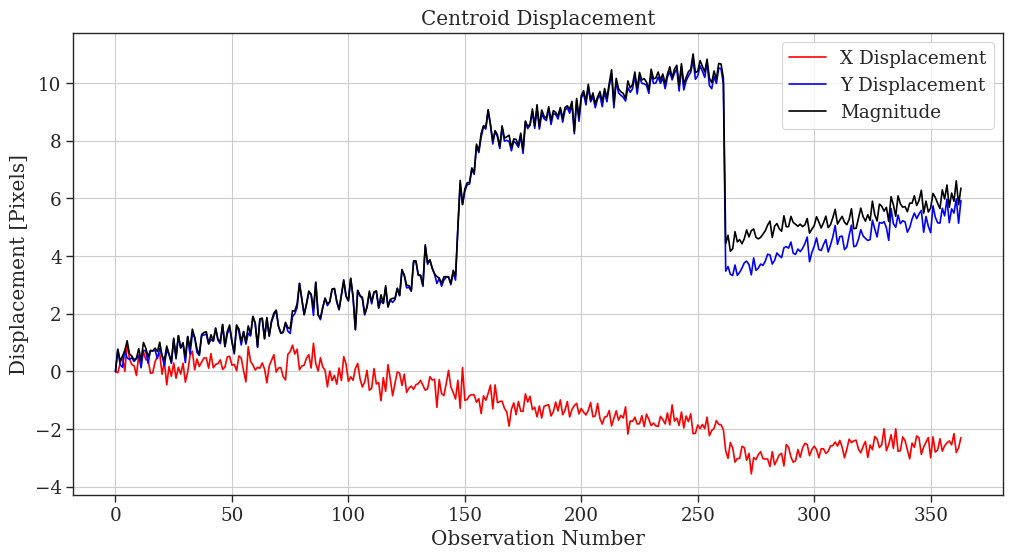

In [9]:
for i, element in enumerate(centroid_x):
    if len(element) != 1:
        print(f"At index {i}, missing centroid")
        
x_motion = np.array([centroid_x[i][0] - centroid_x[0][0] for i in range(len(centroid_x))])
y_motion = np.array([centroid_y[i][0] - centroid_y[0][0] for i in range(len(centroid_y))])
magnitude = np.sqrt(x_motion**2 + y_motion**2)
plt.title("Centroid Displacement")
plt.xlabel("Observation Number")
plt.ylabel("Displacement [Pixels]")
plt.plot(np.arange(0,len(x_motion)),x_motion, label='X Displacement', color="red")
plt.plot(np.arange(0,len(y_motion)),y_motion, label='Y Displacement', color="blue")
plt.plot(np.arange(0,len(magnitude)),magnitude, label='Magnitude', color="black")
plt.legend()
plt.grid()
plt.show()

In [10]:
x, y = [1277],[229] # A new star
x, y, _, _, _ , rad = star_gaussian([x,y], science_np[0], size=box, filter=False)

centroid2_x = []
centroid2_y = []
centroid2_uncertainties = []

box = 20 

# Check all the images to make sure it's lining up nicely :) 
for i in range(len(science_np)):
    new_x = int(np.round(x + x_motion[i]))
    new_y = int(np.round(y + y_motion[i]))
    centroid2_x.append(new_x)
    centroid2_y.append(new_y)
    centroid2_uncertainties.append(uncertainties)
    # vmin,vmax = ZScaleInterval().get_limits(science_np[i])
    # plt.imshow(science_np[i], cmap='cma:lacerta', vmin=vmin,vmax=vmax)
    # plt.scatter(new_x, new_y, c='r', s=5)
    # plt.xlim(new_x-box, new_x+box)
    # plt.ylim(new_y-box, new_y+box)
    # plt.show()   

Found 12 stars


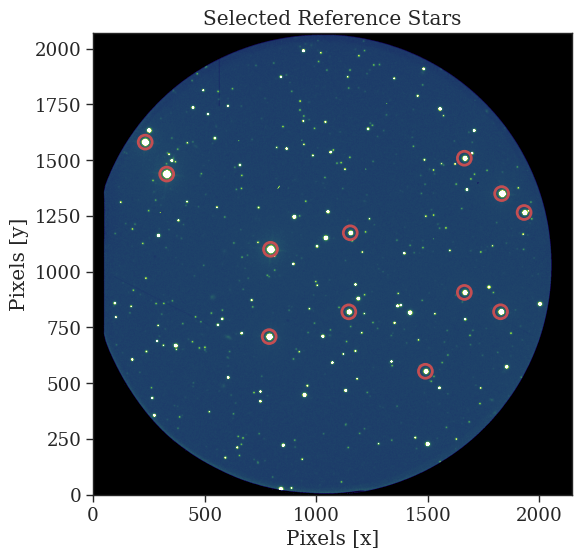

     centroid_x   centroid_y  aperture_radius
0   1489.764102   553.704034         7.534533
1    789.381452   709.090934         7.529313
2   1146.421116   820.188244         7.481783
3   1826.537422   820.477654         7.600862
4   1664.296480   907.261101         7.513147
5    795.393731  1100.569043         9.125436
6   1152.940462  1174.489339         7.449634
7   1932.138879  1265.496467         7.459190
8   1831.364760  1350.219117         8.743756
9    330.055627  1437.771689        10.287593
10  1664.335732  1508.799117         7.414572
11   233.651421  1581.010492         9.575088


In [11]:
threshold = 13000
stars_x = []
stars_y = []
aperture_radius = []

# Find parts of img where intensity > threshold
binary_img = np.where(science_np[0] > threshold, 1, 0)

# Assign each star region a different integer
star_labels, num_stars = label(binary_img)
print(f"Found {num_stars} stars")

# Loop through each region and pick a single point to feed the centroider.
for i in range(1,num_stars+1):
    region_coords = np.where(star_labels == i)
    # Use middle point in each region
    middle_x = np.mean(region_coords[0]).astype(int)
    middle_y = np.mean(region_coords[1]).astype(int) 
    stars_x.append(middle_y)
    stars_y.append(middle_x)
    
size=15
centroid_x, centroid_y, _, _, _, rad = star_gaussian([stars_x, stars_y], science_np[0], size=size)
# Will remove 0, 5, 17, 19 based on proximity to other stars, and positions in the image
centroid_catalog = pd.DataFrame({'centroid_x': centroid_x, 'centroid_y': centroid_y, 'aperture_radius': rad})
# centroid_catalog = centroid_catalog.drop([0,5,17,19])
# centroid_catalog = centroid_catalog.reset_index(drop=True)

vmin, vmax = ZScaleInterval().get_limits(science_np[0])
# for i in range(len(centroid_catalog)):
#     plt.title(f"Reference {i}")
#     plt.imshow(science_np[0], cmap='cma:lacerta', vmin=vmin,vmax=vmax)
#     plt.scatter(centroid_catalog['centroid_x'], centroid_catalog['centroid_y'], c='r', s=5)
#     plt.xlim(centroid_catalog['centroid_x'][i]-size, centroid_catalog['centroid_x'][i]+size)
#     plt.ylim(centroid_catalog['centroid_y'][i]-size, centroid_catalog['centroid_y'][i]+size)
#     plt.show()
plt.imshow(science_np[0], cmap='cma:lacerta', vmin=vmin,vmax=vmax)
plt.scatter(x=centroid_catalog['centroid_x'], y=centroid_catalog['centroid_y'], s=100, facecolors='none', edgecolors='r',lw=2)
plt.title("Selected Reference Stars")
plt.xlabel("Pixels [x]")
plt.ylabel("Pixels [y]")
plt.show()

pp(centroid_catalog)

Now to get flux curves of these stars

In [26]:
gain = 4 # e/DN
def annulus(image, xcenter, ycenter, inner_radius, outer_radius, plot=False):
    ysize, xsize = image.shape
    y, x = np.mgrid[:ysize, :xsize]
    r_squared = (x - xcenter)**2 + (y - ycenter)**2
    mask = (r_squared <= outer_radius**2) & (r_squared >= inner_radius**2)
    annulus_sum = np.sum(image * mask)
    num_pixels = np.sum(mask)
    level_per_pixel = annulus_sum / num_pixels
    
    # Uncertainty
    sigma_bg = np.std(image*mask)
    annulus_uncertainty = np.sqrt(num_pixels * sigma_bg)
    
    if plot:
        plt.xlim(xcenter-20,xcenter+20)
        plt.ylim(ycenter-20,ycenter+20)
        vmin,vmax = ZScaleInterval().get_limits(image)
        plt.imshow(image, vmin=-vmin, vmax = vmax, origin='lower', cmap='cma:lacerta')
        plt.imshow(mask, origin='lower', cmap='gray', alpha=0.6)
        plt.savefig("plt/annulus.pdf")
        plt.show()
    return level_per_pixel, annulus_uncertainty

def aperture(image, xcenter, ycenter, radius, plot=False):
    ysize, xsize = image.shape
    y, x = np.mgrid[:ysize, :xsize]
    mask = ((x - xcenter)**2 + (y - ycenter)**2) <= radius**2
    aperture_sum = np.sum(image * mask)
    if plot:
        plt.xlim(xcenter-20,xcenter+20)
        plt.ylim(ycenter-20,ycenter+20)
        vmin,vmax = ZScaleInterval().get_limits(image)
        plt.imshow(image, vmin=vmin, vmax = vmax, origin='lower', cmap='cma:lacerta')
        plt.imshow(mask, origin='lower', cmap='inferno', alpha=0.6)
        plt.savefig("plt/aperture.pdf")
        plt.show()
    return aperture_sum

flux_database = pd.DataFrame(columns=['Observation', 'star_number', 'centroid_x', 'centroid_y', 'flux', 'uncertainty'])
for i in range(len(science_np)-363):
    print(f"Observation {i}")
    for j in range(len(centroid_catalog)):
        x = centroid_catalog['centroid_x'][j] + x_motion[i]
        y = centroid_catalog['centroid_y'][j] + y_motion[i]
        inner_radius = centroid_catalog['aperture_radius'][j] + 6
        outer_radius = centroid_catalog['aperture_radius'][j] + 12
        annulus_measurement, annulus_uncertainty = annulus(science_np[i], x, y, inner_radius, outer_radius)
        aperture_measurement = aperture(science_np[i], x, y, centroid_catalog['aperture_radius'][j])
        flux = aperture_measurement - annulus_measurement
        obs = pd.DataFrame({'Observation': [i], 'star_number': [j], 'centroid_x': [x], 'centroid_y': [y], 'flux': [flux], 'uncertainty': [annulus_uncertainty]})
        flux_database = pd.concat([flux_database, obs], ignore_index=False)
print(flux_database)        

Observation 0


C:\Users\lwrig\AppData\Local\Temp\ipykernel_23388\2247220718.py:52: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  flux_database = pd.concat([flux_database, obs], ignore_index=False)


  Observation star_number   centroid_x   centroid_y          flux  uncertainty
0           0           0  1489.764102   553.704034  7.204510e+05    26.584795
0           0           1   789.381452   709.090934  2.183411e+06    33.213353
0           0           2  1146.421116   820.188244  9.364259e+05    27.605276
0           0           3  1826.537422   820.477654  1.371242e+06    29.856090
0           0           4  1664.296480   907.261101  8.243568e+05    27.066638
0           0           5   795.393731  1100.569043  4.438009e+06    39.843118
0           0           6  1152.940462  1174.489339  5.418626e+05    25.721952
0           0           7  1932.138879  1265.496467  8.310733e+05    30.457432
0           0           8  1831.364760  1350.219117  2.751542e+06    34.568444
0           0           9   330.055627  1437.771689  4.553563e+06    40.080057
0           0          10  1664.335732  1508.799117  7.801637e+05    26.773227
0           0          11   233.651421  1581.010492 

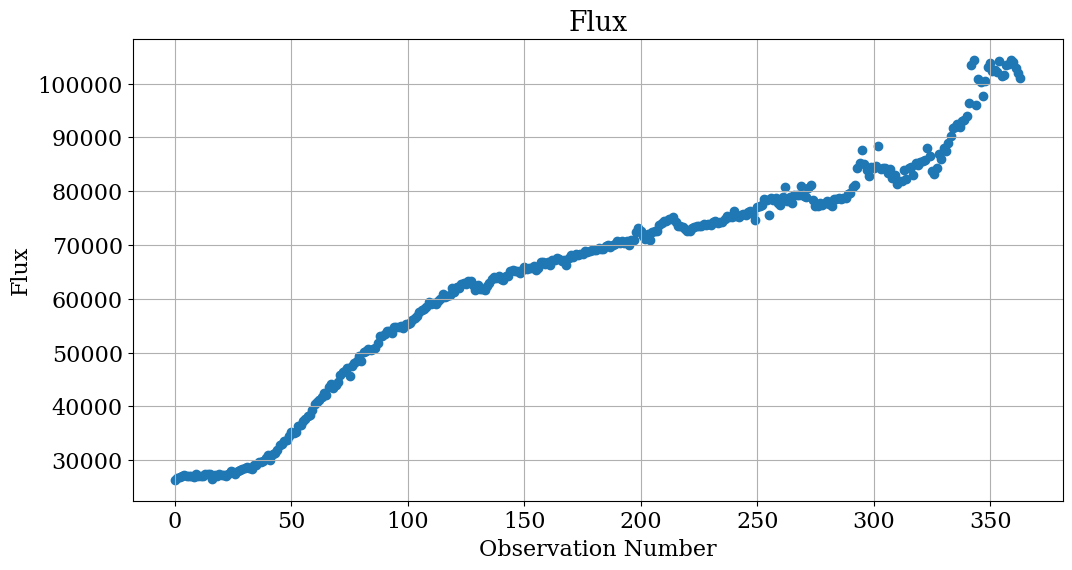

In [ ]:
plt.title("Flux")
plt.xlabel("Observation Number")
plt.ylabel("Flux")
plt.scatter(np.arange(0,len(flux)),flux)
plt.grid()
plt.show()